# Notebook 04 – Context ablation: đưa tiêu đề và mô tả video vào thế nào?

**Câu hỏi nghiên cứu chính của đồ án.** Guideline (mục 1) nói rằng comment cần được hiểu *cùng với tiêu đề và mô tả video*. Vậy:
1. Context có giúp roberta-base không, và giúp subtask nào, lớp nào?
2. Nên đưa context vào theo kiểu nào: **cặp câu** (comment, context) hay **ghép thẳng** thành một chuỗi?
3. Đổi encoder (deberta-v3-base, hoặc model đã học về hate speech) có giúp thêm không?

**Hai cái bẫy cần nhớ khi đọc kết quả** (đã thấy trong EDA và notebook 02–03):
- **Shortcut theo video:** mọi comment cùng video có chung title/description. Model có thể học "video này → nhãn này", nhưng test lại là video mới nên mẹo đó vô dụng. Fold chia theo video giúp ta *đo được* hiện tượng này: nếu model dựa vào shortcut, điểm sẽ giảm chứ không tăng.
- **Bị cắt mất comment:** description dài. Nếu ghép thẳng `title + description + comment` rồi cắt ở N token, phần bị cắt là phần cuối, tức chính comment.

| Mã | Input | max_length | Ghi chú |
|---|---|---|---|
| C0 | comment | 128 | notebook 03 |
| C1 | (comment, title), cặp câu | 128 | |
| C2 | (comment, title + description), cặp câu | 256 | cắt phần dài hơn trước, thường là description |
| C3 | title + description + comment, ghép thẳng | 256 | đối chứng: kiểu đưa context "ngây thơ" |

In [1]:
# Chạy trên Kaggle? Ô này chép bộ dữ liệu + code (dataset bạn đã upload) sang /kaggle/working
# vì /kaggle/input chỉ đọc được, không ghi được. Trên máy nhà ô này tự bỏ qua.
import os
import shutil
from pathlib import Path

if Path("/kaggle/input").exists():
    bundle = next(Path("/kaggle/input").rglob("SemEval2027_Task8")).parent
    work = Path("/kaggle/working/sqe")
    if not work.exists():
        shutil.copytree(bundle, work)
    os.chdir(work / "SemEval2027_Task8" / "notebooks")
    print("Kaggle – thư mục làm việc:", Path.cwd())

Kaggle – thư mục làm việc: /kaggle/working/sqe/SemEval2027_Task8/notebooks


In [2]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sqe").exists())
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

from sqe.data import TASKS, build_inputs, load_en
from sqe.metrics import fmt, fold_scores, paired_delta
from sqe.results import load_oof, log_result
from sqe.train import run_cv

pd.set_option("display.precision", 4)
df = load_en()

VARIANTS = {  # mã → (tên input trong src/sqe/data.py, max_length)
    "C0": ("comment", 128),
    "C1": ("pair_title", 128),
    "C2": ("pair_title_desc", 256),
    "C3": ("concat_tdc", 256),
}

## 1. Trước khi train: mỗi kiểu input giữ lại được bao nhiêu phần comment?

Đếm bằng tokenizer của roberta-base: với mỗi mẫu, bao nhiêu token của *comment* còn sống sau khi cắt về `max_length`.

In [3]:
tok = AutoTokenizer.from_pretrained("roberta-base")
c_len = np.array([len(x) - 2 for x in tok(df["yt_comment"].tolist())["input_ids"]])


def comment_kept(variant, max_len):
    if variant == "comment":
        kept = np.minimum(c_len, max_len - 2)
    elif variant.startswith("pair"):
        a, b = build_inputs(df, variant)
        ids = tok(a, b, truncation=True, max_length=max_len)["input_ids"]
        # roberta cặp câu: <s> comment </s></s> context </s> → comment nằm trước </s> đầu tiên
        kept = np.array([x.index(tok.sep_token_id) - 1 for x in ids])
    else:  # concat_tdc: comment ở CUỐI chuỗi
        prefix = (df["yt_title"] + ". " + df["yt_description"] + ". ").tolist()
        p_len = np.array([len(x) - 2 for x in tok(prefix)["input_ids"]])
        kept = np.clip(max_len - 2 - p_len, 0, c_len)
    return kept


rows = []
for code, (variant, L) in VARIANTS.items():
    kept = comment_kept(variant, L)
    rows.append({"mã": code, "input": variant, "max_length": L,
                 "% comment bị cắt bớt": np.mean(kept < c_len) * 100,
                 "% comment mất HẾT": np.mean(kept <= 0) * 100,
                 "% token comment giữ lại": kept.sum() / c_len.sum() * 100})
pd.DataFrame(rows).round(1)

,mã,input,max_length,% comment bị cắt bớt,% comment mất HẾT,% token comment giữ lại
0,C0,comment,128,4.5,0.0,90.6
1,C1,pair_title,128,5.9,0.0,88.5
2,C2,pair_title_desc,256,2.7,0.0,93.3
3,C3,concat_tdc,256,13.6,8.2,82.3


Kiểu cặp câu gần như giữ nguyên comment, vì tokenizer cắt phần dài hơn (thường là description) trước. Kiểu ghép thẳng (C3) đánh rơi một phần đáng kể comment, kể cả khi đã nới lên 256 token.

## 2. Train C1, C2, C3 cho A và B (roberta-base, cấu hình giống notebook 03)

Mỗi ô train 5 fold × 4 epoch. Độ dài 256 chậm hơn độ dài 128 khoảng 1,4 lần.

In [4]:
for code in ["C1", "C2", "C3"]:
    variant, L = VARIANTS[code]
    for subtask in ["A", "B"]:
        print(f"=== {code} ({variant}, {L}) – Subtask {subtask}")
        oof = run_cv(df, f"roberta_{variant}", dict(model="roberta-base", input=variant, max_length=L),
                     tasks=(subtask,))[subtask]
        log_result("04", "roberta-base", variant, subtask, fold_scores(oof, TASKS[subtask][1]),
                   note=f"{code}, len{L}")

=== C1 (pair_title, 128) – Subtask A
  fold 0: train 2390 | valid 599
    epoch 1: loss 0.6601 | val macro-F1 A 0.7106
    epoch 2: loss 0.5205 | val macro-F1 A 0.7544
    epoch 3: loss 0.3627 | val macro-F1 A 0.7449
    epoch 4: loss 0.2280 | val macro-F1 A 0.7409
  fold 1: train 2390 | valid 599
    epoch 1: loss 0.6559 | val macro-F1 A 0.6999
    epoch 2: loss 0.5052 | val macro-F1 A 0.7595
    epoch 3: loss 0.3432 | val macro-F1 A 0.7116
    epoch 4: loss 0.2079 | val macro-F1 A 0.7350
  fold 2: train 2392 | valid 597
    epoch 1: loss 0.6680 | val macro-F1 A 0.6917
    epoch 2: loss 0.5234 | val macro-F1 A 0.6992
    epoch 3: loss 0.3783 | val macro-F1 A 0.7269
    epoch 4: loss 0.2394 | val macro-F1 A 0.7325
  fold 3: train 2392 | valid 597
    epoch 1: loss 0.6555 | val macro-F1 A 0.6828
    epoch 2: loss 0.5068 | val macro-F1 A 0.6895
    epoch 3: loss 0.3635 | val macro-F1 A 0.7034
    epoch 4: loss 0.2352 | val macro-F1 A 0.7146
  fold 4: train 2392 | valid 597
    epoch 1: l

## 3. Bảng ablation

In [5]:
def ablation_table(model_prefix="roberta"):
    rows = []
    for subtask in ["A", "B"]:
        labels = TASKS[subtask][1]
        base = fold_scores(load_oof(f"{model_prefix}_comment", subtask), labels)
        for code, (variant, L) in VARIANTS.items():
            sc = fold_scores(load_oof(f"{model_prefix}_{variant}", subtask), labels)
            d = paired_delta(sc, base)
            rows.append({"subtask": subtask, "mã": code, "input": variant,
                         "macro_f1": sc.macro_f1.mean(), "std": sc.macro_f1.std(ddof=0),
                         "Δ so với C0": d["delta_mean"] if code != "C0" else np.nan,
                         "thắng C0 (fold)": f"{d['wins']}/5" if code != "C0" else "",
                         **{c: sc[c].mean() for c in sc.columns if c.startswith("f1_")}})
    return pd.DataFrame(rows)


abl = ablation_table()
abl

,subtask,mã,input,macro_f1,std,Δ so với C0,thắng C0 (fold),f1_no,f1_yes,f1_yes_implicit,f1_yes_explicit
0,A,C0,comment,0.7274,0.0098,NaN,,0.7590,0.6958,NaN,NaN
1,A,C1,pair_title,0.7266,0.0120,-0.0008,2/5,0.7618,0.6915,NaN,NaN
2,A,C2,pair_title_desc,0.7288,0.0053,0.0014,3/5,0.7627,0.6949,NaN,NaN
3,A,C3,concat_tdc,0.7113,0.0162,-0.0161,1/5,0.7494,0.6732,NaN,NaN
4,B,C0,comment,0.5856,0.0179,NaN,,0.7311,NaN,0.4332,0.5925
5,B,C1,pair_title,0.5808,0.0090,-0.0048,1/5,0.7361,NaN,0.4184,0.5878
6,B,C2,pair_title_desc,0.5692,0.0173,-0.0164,1/5,0.7362,NaN,0.3806,0.5908
7,B,C3,concat_tdc,0.5506,0.0150,-0.0350,1/5,0.7127,NaN,0.3701,0.5690


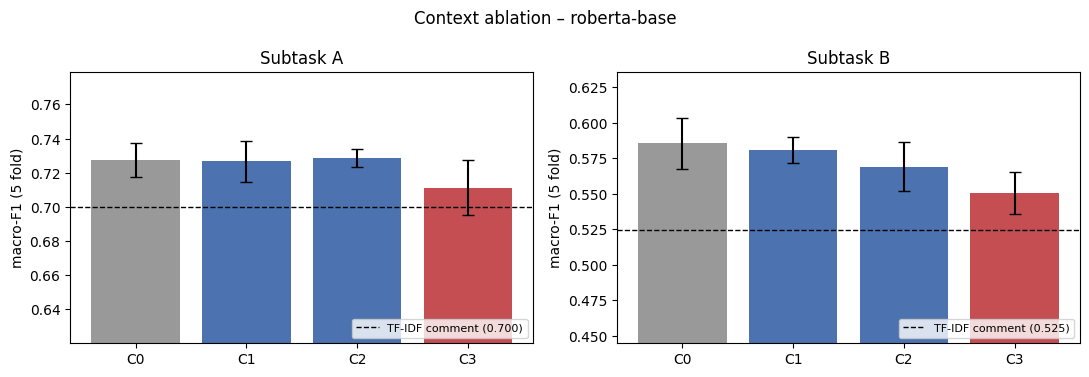

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, subtask in zip(axes, ["A", "B"]):
    t = abl[abl.subtask == subtask]
    ax.bar(t["mã"], t["macro_f1"], yerr=t["std"], capsize=4, color=["#999", "#4c72b0", "#4c72b0", "#c44e52"])
    tf = fold_scores(load_oof("tfidf_comment", subtask), TASKS[subtask][1]).macro_f1.mean()
    ax.axhline(tf, ls="--", c="k", lw=1, label=f"TF-IDF comment ({tf:.3f})")
    ax.set_ylim(min(t["macro_f1"].min(), tf) - 0.08, t["macro_f1"].max() + 0.05)
    ax.set_title(f"Subtask {subtask}")
    ax.set_ylabel("macro-F1 (5 fold)")
    ax.legend(loc="lower right", fontsize=8)
plt.suptitle("Context ablation – roberta-base")
plt.tight_layout()
plt.savefig(ROOT / "outputs/results/context_ablation.png", dpi=150)
plt.show()

**Từng lớp thay đổi ra sao khi thêm context?** Bảng dưới là F1 từng lớp của mỗi biến thể trừ đi F1 của C0 (dương = context giúp lớp đó).

In [7]:
per_class = []
for subtask in ["A", "B"]:
    t = abl[abl.subtask == subtask].set_index("mã")
    f1_cols = [c for c in t.columns if c.startswith("f1_") and t[c].notna().all()]
    per_class.append((t[f1_cols] - t.loc["C0", f1_cols]).drop(index="C0").assign(subtask=subtask))
pd.concat(per_class).round(4)

,f1_no,f1_yes,subtask,f1_yes_implicit,f1_yes_explicit
mã,,,,,
C1,0.0028,-0.0043,A,NaN,NaN
C2,0.0037,-0.0008,A,NaN,NaN
C3,-0.0097,-0.0226,A,NaN,NaN
C1,0.005,NaN,B,-0.0148,-0.0047
C2,0.0052,NaN,B,-0.0526,-0.0017
C3,-0.0184,NaN,B,-0.0631,-0.0235


## 4. Chọn input tốt nhất cho từng subtask

**Quy tắc (đặt trước khi nhìn kết quả):** chỉ chọn một biến thể có context nếu nó có điểm trung bình cao nhất **và** thắng C0 ở ít nhất 4/5 fold. Nếu không, giữ C0 vì nó đơn giản hơn. Chênh lệch nhỏ mà chỉ thắng 3/5 fold thì coi như ngang nhau, không đủ căn cứ để kết luận là tốt hơn.

In [8]:
best_input = {}
for subtask in ["A", "B"]:
    t = abl[abl.subtask == subtask].sort_values("macro_f1", ascending=False)
    top = t.iloc[0]
    ok = top["mã"] == "C0" or int(str(top["thắng C0 (fold)"]).split("/")[0]) >= 4
    best_input[subtask] = top["input"] if ok else "comment"
    print(f"Subtask {subtask}: cao nhất = {top['mã']} ({top['input']}, {top['macro_f1']:.4f}, "
          f"thắng C0 {top['thắng C0 (fold)'] or '-'}) → chọn: {best_input[subtask]}")

Subtask A: cao nhất = C2 (pair_title_desc, 0.7288, thắng C0 3/5) → chọn: comment
Subtask B: cao nhất = C0 (comment, 0.5856, thắng C0 -) → chọn: comment


## 5. Đổi encoder (với input tốt nhất vừa chọn)

- **`microsoft/deberta-v3-base`**: thường mạnh hơn roberta-base ở các bài phân loại câu. Model lớn hơn (184 triệu tham số), nên dùng batch 8 × tích luỹ gradient 2 cho vừa GPU 4 GB, kích thước batch hiệu dụng vẫn là 16.
- **`cardiffnlp/twitter-roberta-base-hate-latest`**: roberta-base đã học thêm trên tweet và đã fine-tune cho bài phát hiện hate speech (nhị phân). Câu hỏi đặt ra: kiến thức "domain" này có chuyển sang được không? Ta chỉ dùng phần encoder, head được khởi tạo mới.

In [9]:
from sqe.data import INPUT_MAXLEN as LEN
from sqe.train import ENCODERS

for short in ["deberta", "twhate"]:
    enc_cfg = ENCODERS[short]
    for subtask in ["A", "B"]:
        variant = best_input[subtask]
        print(f"=== {short} – {variant} – Subtask {subtask}")
        oof = run_cv(df, f"{short}_{variant}", dict(enc_cfg, input=variant, max_length=LEN[variant]),
                     tasks=(subtask,))[subtask]
        log_result("04", enc_cfg["model"], variant, subtask, fold_scores(oof, TASKS[subtask][1]),
                   note=f"đổi encoder, len{LEN[variant]}")

=== deberta – comment – Subtask A
  fold 0: train 2390 | valid 599
    epoch 1: loss nan | val macro-F1 A 0.3573
    epoch 2: loss nan | val macro-F1 A 0.3573
    epoch 3: loss nan | val macro-F1 A 0.3573
    epoch 4: loss nan | val macro-F1 A 0.3573
  fold 1: train 2390 | valid 599
    epoch 1: loss nan | val macro-F1 A 0.3580
    epoch 2: loss nan | val macro-F1 A 0.3580
    epoch 3: loss nan | val macro-F1 A 0.3580
    epoch 4: loss nan | val macro-F1 A 0.3580
  fold 2: train 2392 | valid 597
    epoch 1: loss nan | val macro-F1 A 0.3574
    epoch 2: loss nan | val macro-F1 A 0.3574
    epoch 3: loss nan | val macro-F1 A 0.3574
    epoch 4: loss nan | val macro-F1 A 0.3574
  fold 3: train 2392 | valid 597
    epoch 1: loss nan | val macro-F1 A 0.3574
    epoch 2: loss nan | val macro-F1 A 0.3574
    epoch 3: loss nan | val macro-F1 A 0.3574
    epoch 4: loss nan | val macro-F1 A 0.3574
  fold 4: train 2392 | valid 597
    epoch 1: loss nan | val macro-F1 A 0.3574
    epoch 2: loss n

In [10]:
rows = []
for subtask in ["A", "B"]:
    labels, variant = TASKS[subtask][1], best_input[subtask]
    base = fold_scores(load_oof(f"roberta_{variant}", subtask), labels)
    for short, label in [("roberta", "roberta-base"), ("deberta", "deberta-v3-base"),
                         ("twhate", "twitter-roberta-hate")]:
        sc = fold_scores(load_oof(f"{short}_{variant}", subtask), labels)
        d = paired_delta(sc, base)
        rows.append({"subtask": subtask, "encoder": label, "input": variant,
                     "macro_f1": sc.macro_f1.mean(), "std": sc.macro_f1.std(ddof=0),
                     "Δ so với roberta": d["delta_mean"] if short != "roberta" else np.nan,
                     "thắng roberta (fold)": f"{d['wins']}/5" if short != "roberta" else "",
                     **{c: sc[c].mean() for c in sc.columns if c.startswith("f1_")}})
enc_table = pd.DataFrame(rows)
enc_table

,subtask,encoder,input,macro_f1,std,Δ so với roberta,thắng roberta (fold),f1_no,f1_yes,f1_yes_implicit,f1_yes_explicit
0,A,roberta-base,comment,0.7274,9.7725e-03,NaN,,0.7590,0.6958,NaN,NaN
1,A,deberta-v3-base,comment,0.3575,2.5410e-04,-0.3699,0/5,0.7150,0.0000,NaN,NaN
2,A,twitter-roberta-hate,comment,0.7335,1.1522e-02,0.0061,3/5,0.7649,0.7020,NaN,NaN
3,B,roberta-base,comment,0.5856,1.7904e-02,NaN,,0.7311,NaN,0.4332,0.5925
4,B,deberta-v3-base,comment,0.2134,1.4778e-05,-0.3722,0/5,0.6401,NaN,0.0000,0.0000
5,B,twitter-roberta-hate,comment,0.5870,1.1365e-02,0.0015,3/5,0.7364,NaN,0.4246,0.6001


## 6. Kết luận

*(phần này được viết sau khi chạy xong, dựa trên số liệu ở trên)*